# N9 — Is max-pooling the cause?

### What is already established

Measured on the published weights, no retraining:

| pooling | a bright cell affects | a dark cell affects | asymmetry |
|---|---|---|---|
| **max** (published) | 7 of 36 bits | 3 of 36 bits | **2.33x** |
| **avg** | 4 bits | 4 bits | **1.00x** |

`max_pool2d` propagates the maximum, so a bright region wins every pooling window it touches and
its influence spreads. A dark region at 0.0 wins none and stays local. That asymmetry is
consistent with every curve in N6-N8: arm A degrading monotonically with occluder brightness,
arms B and E cliffing at black, and augmentation being unable to fix black occluders.

But substituting the pooling at *inference* changes the function the weights were trained for, so
only the influence pattern is valid from that test — not accuracy.

### What this notebook adds

Two decoders trained **from identical data with identical seeds, differing only in the pooling
layer**:

| arm | pooling |
|---|---|
| **M** | max (reproduces the published architecture) |
| **G** | average |

Arm M is trained here rather than reusing arm B, so pooling is the only thing that differs.
Comparing against B would confound pooling with data-generation and seed differences.

**Prediction.** If max-pooling causes the spillover, arm G's visible-cell error should be far
flatter across occluder intensity than arm M's. If both slope equally, max-pooling is not the
cause and the mechanism claim must be dropped.

Runtime: about 45 minutes on a T4.

## 1. Setup

In [1]:
RUN_ON = 'dev'

import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch, h5py
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives'
CK9 = f'{BASE}/ckpt_n9'; os.makedirs(CK9, exist_ok=True); os.makedirs(WORK, exist_ok=True)

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1',
                    'https://github.com/AVAuco/deeparuco.git', REPO], check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits

def load_weights_safe(p):
    store = {}
    with h5py.File(p,'r') as f:
        root = f['model_weights'] if 'model_weights' in f else f
        def walk(g, pre=''):
            for k in g.keys():
                try: o = g[k]
                except (KeyError, OSError): continue
                q = f'{pre}/{k}'
                if isinstance(o, h5py.Dataset): store[q] = np.array(o)
                elif isinstance(o, h5py.Group): walk(o, q)
        walk(root)
    def pick(l, s):
        h = [k for k in store if f'/{l}/' in k and k.endswith(s)]
        assert len(h)==1, f'{l}:{s} -> {h}'
        return store[h[0]]
    w = {'c1_w':pick('conv2d','kernel:0'),'c1_b':pick('conv2d','bias:0'),'p1_a':pick('p_re_lu','alpha:0'),
         'c2_w':pick('conv2d_1','kernel:0'),'c2_b':pick('conv2d_1','bias:0'),'p2_a':pick('p_re_lu_1','alpha:0'),
         'c3_w':pick('conv2d_2','kernel:0'),'c3_b':pick('conv2d_2','bias:0')}
    for k,s in {'c1_w':(5,5,1,8),'c1_b':(8,),'p1_a':(28,28,8),'c2_w':(3,3,8,4),
                'c2_b':(4,),'p2_a':(12,12,4),'c3_w':(1,1,4,1),'c3_b':(1,)}.items():
        assert w[k].shape==s, f'{k}: {w[k].shape} != {s}'
    return w

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
assert DEV_.type == 'cuda', ('GPU required. Runtime > Change runtime type > T4 GPU, '
                             'then re-run. On CPU this takes ~2 hours.')
splits = json.load(open(f'{ART}/splits.json'))
VIEWS  = splits['dev'] if RUN_ON=='dev' else [splits['heldout'][0]]
STRIDE = splits['benchmark_stride']
Wk  = load_weights_safe(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
FLY = f'{WORK}/flyingarucov2'
if not os.path.isdir(FLY):
    os.makedirs(FLY, exist_ok=True)
    subprocess.run(['tar','-xzf',f'{CACHE}/flyingarucov2.tar.gz','-C',FLY], check=True)
fly_json = sorted(glob.glob(f'{FLY}/**/*.json', recursive=True))
print(f'{torch.cuda.get_device_name(0)} | views {VIEWS} | flying-aruco {len(fly_json)}')

Mounted at /content/drive
Tesla T4 | views ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | flying-aruco 2500


## 2. Pipeline

In [2]:
r_int = lambda v: int(round(v))
def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]
def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))
def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)
def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out
def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)
def strip_box(img, corners, level, key, mid):
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
    box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
           (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None
def apply_box(img, box, value):
    if box is None: return img, np.zeros(img.shape[:2], np.uint8)
    a,b,c,d = box
    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)
    out[b:d,a:c] = int(value); mk[b:d,a:c] = 255
    return out, mk
def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out
def dec_soft(P):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)
print('pipeline ready')

pipeline ready


## 3. Two decoders differing only in pooling

Everything else is identical: same conv shapes, same per-element PReLU, same initialisation seed.

In [3]:
class SpatialPReLU(nn.Module):
    def __init__(s,c,h,w): super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s,x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)

class Decoder(nn.Module):
    def __init__(s, pooling='max'):
        super().__init__()
        assert pooling in ('max','avg')
        s.pooling = pooling
        s.c1=nn.Conv2d(1,8,5); s.p1=SpatialPReLU(8,28,28)
        s.c2=nn.Conv2d(8,4,3); s.p2=SpatialPReLU(4,12,12)
        s.c3=nn.Conv2d(4,1,1)
    def pool(s,x):
        return F.max_pool2d(x,2) if s.pooling=='max' else F.avg_pool2d(x,2)
    def forward(s,x):
        x=s.pool(s.p1(s.c1(x))); x=s.pool(s.p2(s.c2(x)))
        return s.c3(x)[:,0]

for p in ('max','avg'):
    m = Decoder(p)
    assert m(torch.zeros(2,1,32,32)).shape == (2,6,6)
    print(f'{p}-pool decoder: {sum(q.numel() for q in m.parameters())} params')
print('identical parameter counts — pooling is the only difference')

max-pool decoder: 7353 params
avg-pool decoder: 7353 params
identical parameter counts — pooling is the only difference


## 4. Training data (shared by both arms)

In [4]:
def bits_for(mid, rot, conv):
    b = CB[mid]; k = rot if conv in (0,1) else -rot
    return np.rot90(b, k) if conv in (0,2) else np.rot90(b, -k)

def np_decode_published(x32):
    def cv(x,w,b):
        kh,kw,_,_=w.shape
        return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
    def pl(x):
        N,H,Wd,Cc=x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
    x=np.asarray(x32,np.float32)[...,None]
    x=pl(np.where((y:=cv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
    x=pl(np.where((y:=cv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
    return (1/(1+np.exp(-np.clip(cv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60)))).astype(np.float32)

probe=[]
for jp in fly_json[:60]:
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    for m in json.load(open(jp))['markers'][:4]:
        x32,_ = prepare(img, np.zeros(img.shape[:2],np.uint8), get_corners(m))
        if x32 is None: continue
        probe.append((np_decode_published(x32[None])[0], int(m['id']),
                      int(m.get('rot', m.get('rotation', 0)))))
scores = {c: np.mean([np.mean((p>0.5).astype(np.uint8)==bits_for(i,r,c)) for p,i,r in probe]) for c in range(4)}
CONV = max(scores, key=scores.get)
assert scores[CONV] > 0.90, f'rotation convention unresolved: {scores}'
print(f'rotation convention {CONV} ({scores[CONV]:.4f})\n')

OCC_TRAIN, N_SAMPLES = [0.0, 0.10, 0.20, 0.25, 0.35, 0.45, 0.55], 5
X, Y = [], []
t0=time.time()
for n, jp in enumerate(fly_json):
    img = cv2.imread(jp.replace('.json','.jpg'), cv2.IMREAD_GRAYSCALE)
    if img is None: continue
    key = os.path.basename(jp)
    for m in json.load(open(jp))['markers']:
        cn, mid = get_corners(m), int(m['id'])
        if mid >= 250: continue
        bits = bits_for(mid, int(m.get('rot', m.get('rotation', 0))), CONV)
        rng = np.random.default_rng(zlib.crc32(f'n9|{key}|{mid}'.encode()))
        for L in rng.choice(OCC_TRAIN, N_SAMPLES, replace=False):
            v = int(rng.integers(0,256))
            oi, om = apply_box(img, strip_box(img, cn, float(L), key, mid) if L>0 else None, v)
            x32, _ = prepare(oi, om, cn)
            if x32 is None: continue
            X.append((x32*255).astype(np.uint8)); Y.append(bits)
    if n % 600 == 0: print(f'  {n}/{len(fly_json)} ({time.time()-t0:.0f}s) crops={len(X)}')
X = np.stack(X); Y = np.stack(Y).astype(np.float32)
idx = np.random.default_rng(42).permutation(len(X)); cut = int(0.9*len(X))
tr, va = idx[:cut], idx[cut:]
print(f'\n{len(X)} crops | train {len(tr)} val {len(va)}')

rotation convention 0 (0.9912)

  0/2500 (0s) crops=40
  600/2500 (16s) crops=15560
  1200/2500 (32s) crops=30945
  1800/2500 (48s) crops=46665
  2400/2500 (65s) crops=62275

64840 crops | train 58356 val 6484


## 5. Train both arms

In [5]:
def augment(xb, bb, rng):
    k, fl = rng.integers(0,4), rng.integers(0,3)
    if k: xb = np.rot90(xb,k,axes=(1,2)); bb = np.rot90(bb,k,axes=(1,2))
    if fl==1: xb, bb = xb[:,:,::-1], bb[:,:,::-1]
    elif fl==2: xb, bb = xb[:,::-1,:], bb[:,::-1,:]
    return np.ascontiguousarray(xb), np.ascontiguousarray(bb)

EPOCHS, PATIENCE, BS = 200, 20, 256
def run_epoch(model, ids, opt=None, rng=None):
    train = opt is not None; model.train(train); tot=n=0
    order = np.random.permutation(ids) if train else ids
    with torch.set_grad_enabled(train):
        for s in range(0, len(order), BS):
            b = order[s:s+BS]; xb, bb = X[b], Y[b]
            if train: xb, bb = augment(xb, bb, rng)
            xb = torch.tensor(xb, dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            bb = torch.tensor(bb).to(DEV_)
            loss = F.binary_cross_entropy_with_logits(model(xb), bb)
            if train: opt.zero_grad(); loss.backward(); opt.step()
            tot += float(loss)*len(b); n += len(b)
    return tot/n

nets, curves = {}, {}
for arm, pooling in [('M','max'), ('G','avg')]:
    torch.manual_seed(42); rng = np.random.default_rng(42)      # identical seeds
    net = Decoder(pooling).to(DEV_)
    opt = torch.optim.Adam(net.parameters(), 1e-3)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
    best, bad, hist, t0 = 1e9, 0, [], time.time()
    for ep in range(EPOCHS):
        trl = run_epoch(net, tr, opt, rng); vl = run_epoch(net, va)
        sch.step(vl); hist.append((trl, vl))
        if vl < best - 1e-5:
            best, bad = vl, 0; torch.save(net.state_dict(), f'{CK9}/arm_{arm}.pt')
        else:
            bad += 1
            if bad >= PATIENCE: print(f'  arm {arm}: early stop at {ep}'); break
        if ep % 25 == 0: print(f'  arm {arm} ({pooling}) ep{ep:3d} val {vl:.4f} ({time.time()-t0:.0f}s)')
    net.load_state_dict(torch.load(f'{CK9}/arm_{arm}.pt')); net.eval()
    nets[arm], curves[arm] = net, hist
    print(f'arm {arm} ({pooling}): best val {best:.4f} | {time.time()-t0:.0f}s\n')

print('CLEAN-CASE PARITY CHECK — the two arms must be comparably good before')
print('any robustness difference between them is interpretable.')
for arm in ('M','G'):
    print(f'  arm {arm}: val loss {min(h[1] for h in curves[arm]):.4f}')

/tmp/ipykernel_2192/2098747751.py:20: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  tot += float(loss)*len(b); n += len(b)


  arm M (max) ep  0 val 0.2971 (2s)
  arm M (max) ep 25 val 0.1707 (22s)
  arm M (max) ep 50 val 0.1635 (42s)
  arm M (max) ep 75 val 0.1597 (63s)
  arm M (max) ep100 val 0.1592 (83s)
  arm M: early stop at 122
arm M (max): best val 0.1586 | 100s

  arm G (avg) ep  0 val 0.3046 (1s)
  arm G (avg) ep 25 val 0.1833 (21s)
  arm G (avg) ep 50 val 0.1715 (41s)
  arm G (avg) ep 75 val 0.1648 (61s)
  arm G (avg) ep100 val 0.1619 (82s)
  arm G (avg) ep125 val 0.1612 (102s)
  arm G (avg) ep150 val 0.1584 (122s)
  arm G: early stop at 162
arm G (avg): best val 0.1574 | 131s

CLEAN-CASE PARITY CHECK — the two arms must be comparably good before
any robustness difference between them is interpretable.
  arm M: val loss 0.1586
  arm G: val loss 0.1574


## 6. Influence measurement on the trained arms

The same test that gave 2.33x for max and 1.00x for avg on the published weights, now on decoders
actually trained with each pooling.

In [6]:
def influence(net):
    base = torch.full((1,1,32,32), 0.5, device=DEV_)
    with torch.no_grad():
        p0 = torch.sigmoid(net(base))[0].cpu().numpy()
        out = {}
        for v, lbl in [(0.0,'dark'), (1.0,'bright')]:
            x = base.clone(); x[0,0,12:16,12:16] = v
            d = np.abs(torch.sigmoid(net(x))[0].cpu().numpy() - p0)
            out[lbl] = int((d > 1e-3).sum())
    return out

print(f"{'arm':>5}{'pooling':>9}{'bright bits':>13}{'dark bits':>11}{'asymmetry':>12}")
print('-'*50)
for arm, pooling in [('M','max'), ('G','avg')]:
    r = influence(nets[arm])
    print(f'{arm:>5}{pooling:>9}{r["bright"]:>13}{r["dark"]:>11}'
          f'{r["bright"]/max(r["dark"],1):>12.2f}x')
print('\npublished weights, for reference: max 7/3 = 2.33x, avg 4/4 = 1.00x')

  arm  pooling  bright bits  dark bits   asymmetry
--------------------------------------------------
    M      max            9          9        1.00x
    G      avg            9          9        1.00x

published weights, for reference: max 7/3 = 2.33x, avg 4/4 = 1.00x


## 7. Intensity sweep on Shadow-ArUco

In [7]:
INTENS = [0, 64, 127, 192, 255]
LEVEL  = 0.50
SW = {v: {'x':[], 'id':[], 'mask':[]} for v in INTENS}
t0=time.time()
for vid in VIEWS:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            box = strip_box(img, cn, LEVEL, key, mid)
            for v in INTENS:
                oi, om = apply_box(img, box, v)
                x32, occ = prepare(oi, om, cn)
                if x32 is None: continue
                SW[v]['x'].append((x32*255).astype(np.uint8))
                SW[v]['id'].append(mid); SW[v]['mask'].append(occ)
    print(f'  {vid} ({time.time()-t0:.0f}s)')
for v in INTENS:
    for k in SW[v]: SW[v][k] = np.array(SW[v][k])
n = len(SW[0]['id']); assert n > 2000, f'only {n} markers'
print(f'\n{n} markers per intensity, {SW[0]["mask"].sum(axis=(1,2)).mean():.1f} cells hidden')

def torch_probs(net, x8, chunk=8192):
    ps=[]
    with torch.no_grad():
        for s in range(0,len(x8),chunk):
            xb = torch.tensor(x8[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            ps.append(torch.sigmoid(net(xb)).cpu().numpy())
    return np.concatenate(ps)

def true_oriented(P, ids):
    obs=(P>0.5).astype(np.uint8); out=np.empty_like(obs)
    for i in range(len(P)):
        ref=CB[ids[i]]; best,bk=99,0
        for k in range(4):
            h=int(np.sum(np.rot90(obs[i],k)!=ref))
            if h<best: best,bk=h,k
        out[i]=np.rot90(ref,-bk)
    return out

RES = {}
for arm in ('M','G'):
    RES[arm] = {}
    for v in INTENS:
        P = torch_probs(nets[arm], SW[v]['x'])
        T = true_oriented(P, SW[v]['id']); M = SW[v]['mask']
        err = (P>0.5).astype(np.uint8) != T
        RES[arm][v] = {'acc': float((dec_soft(P)==SW[v]['id']).mean()),
                       'err_vis': float(err[~M].mean()),
                       'conf_occ': float((np.abs(P-0.5)*2)[M].mean())}
    print(f'arm {arm} evaluated')

  video_1 (16s)
  video_2 (29s)
  video_3 (44s)
  video_4 (59s)
  video_5 (71s)

12276 markers per intensity, 18.0 cells hidden
arm M evaluated
arm G evaluated


## 8. Verdict

  arm   pool         0        64       127       192       255     slope       r
--------------------------------------------------------------------------------
    M    max     0.107     0.059     0.072     0.088     0.101    -0.006   0.137
    G    avg     0.098     0.063     0.075     0.081     0.091    -0.007   0.047
  (error on VISIBLE cells — spillover)

  arm   pool         0        64       127       192       255    spread
------------------------------------------------------------------------
    M    max     38.3%     90.2%     85.1%     79.5%     74.2%     51.9p
    G    avg     42.6%     87.5%     80.9%     76.7%     72.0%     44.9p
  (ID accuracy)

max-pool spillover slope : -0.006
avg-pool spillover slope : -0.007
reduction                : 18%

INCONCLUSIVE: arm M shows little spillover, so there is nothing to remove.
Check the clean-case parity in section 5 before interpreting.


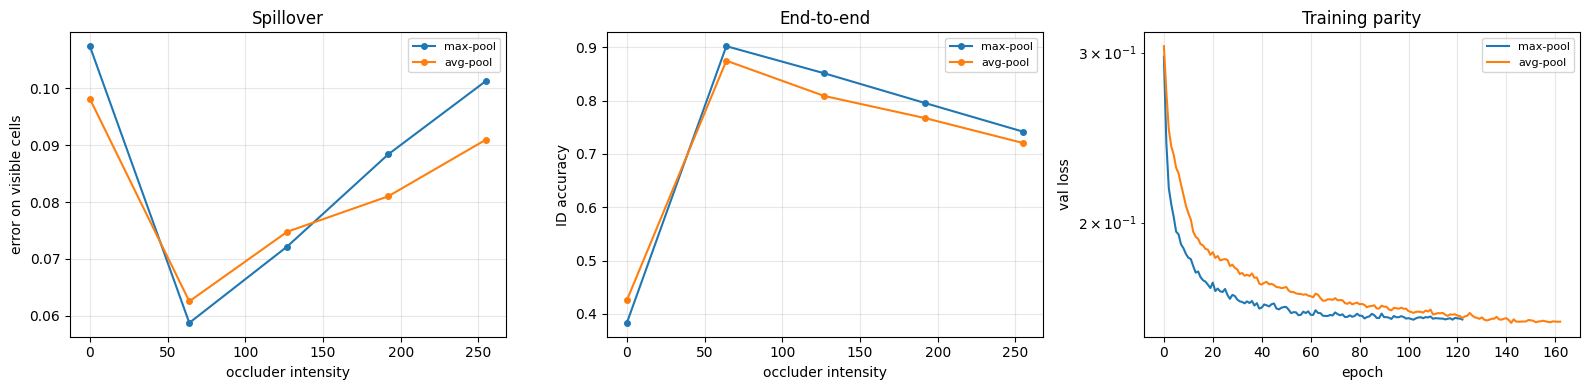


saved -> /content/drive/MyDrive/aruco_p2/artifacts/n9_pooling_dev.json | checkpoints /content/drive/MyDrive/aruco_p2/ckpt_n9


In [8]:
print(f"{'arm':>5}{'pool':>7}" + ''.join(f'{v:>10}' for v in INTENS) + f"{'slope':>10}{'r':>8}")
print('-'*(12+10*len(INTENS)+18))
slopes = {}
for arm, pooling in [('M','max'), ('G','avg')]:
    e = np.array([RES[arm][v]['err_vis'] for v in INTENS])
    r = float(np.corrcoef(np.array(INTENS,float), e)[0,1])
    slopes[arm] = e[-1]-e[0]
    print(f'{arm:>5}{pooling:>7}' + ''.join(f'{x:>10.3f}' for x in e) + f'{e[-1]-e[0]:>10.3f}{r:>8.3f}')
print('  (error on VISIBLE cells — spillover)\n')

print(f"{'arm':>5}{'pool':>7}" + ''.join(f'{v:>10}' for v in INTENS) + f"{'spread':>10}")
print('-'*(12+10*len(INTENS)+10))
for arm, pooling in [('M','max'), ('G','avg')]:
    a = [RES[arm][v]['acc'] for v in INTENS]
    print(f'{arm:>5}{pooling:>7}' + ''.join(f'{x:>10.1%}' for x in a) + f'{(max(a)-min(a))*100:>9.1f}p')
print('  (ID accuracy)\n')

red = (slopes['M'] - slopes['G']) / abs(slopes['M']) * 100 if abs(slopes['M']) > 1e-6 else float('nan')
print(f"max-pool spillover slope : {slopes['M']:+.3f}")
print(f"avg-pool spillover slope : {slopes['G']:+.3f}")
print(f"reduction                : {red:.0f}%\n")

if slopes['M'] > 0.03 and slopes['G'] < 0.4*slopes['M']:
    print('CAUSAL. Replacing max-pooling with average pooling removes most of the')
    print('brightness-dependent spillover. The asymmetry of max-pooling is the mechanism,')
    print('and this is a concrete architectural fix for fiducial decoders.')
elif slopes['M'] > 0.03:
    print('NOT CAUSAL (or only partly). Both poolings slope similarly — max-pooling is not')
    print('the explanation. Report the influence measurement as an architectural property')
    print('only, and drop the causal claim.')
else:
    print('INCONCLUSIVE: arm M shows little spillover, so there is nothing to remove.')
    print('Check the clean-case parity in section 5 before interpreting.')

fig, ax = plt.subplots(1,3, figsize=(16,4))
for arm, lbl in [('M','max-pool'), ('G','avg-pool')]:
    ax[0].plot(INTENS, [RES[arm][v]['err_vis'] for v in INTENS], '-o', ms=4, label=lbl)
    ax[1].plot(INTENS, [RES[arm][v]['acc'] for v in INTENS], '-o', ms=4, label=lbl)
    ax[2].plot([h[1] for h in curves[arm]], label=lbl)
ax[0].set_xlabel('occluder intensity'); ax[0].set_ylabel('error on visible cells')
ax[0].set_title('Spillover'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
ax[1].set_xlabel('occluder intensity'); ax[1].set_ylabel('ID accuracy')
ax[1].set_title('End-to-end'); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
ax[2].set_xlabel('epoch'); ax[2].set_ylabel('val loss'); ax[2].set_yscale('log')
ax[2].set_title('Training parity'); ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()

json.dump({'run_on': RUN_ON, 'views': VIEWS, 'intensities': INTENS, 'n_markers': int(n),
           'results': {f'{a}_{v}': RES[a][v] for a in ('M','G') for v in INTENS},
           'slopes': {k: float(v) for k,v in slopes.items()}, 'reduction_pct': float(red),
           'val_loss': {a: float(min(h[1] for h in curves[a])) for a in ('M','G')}},
          open(f'{ART}/n9_pooling_{RUN_ON}.json','w'), indent=1)
print(f'\nsaved -> {ART}/n9_pooling_{RUN_ON}.json | checkpoints {CK9}')